# Python과 가상환경

**이 노트북에서 할 일**

1. 이 노트북을 실행하는 Python의 버전과 가상환경 여부를 확인합니다.
2. 임시 폴더에 가상환경 `env_a`와 `env_b`를 만들고, 두 환경의 폴더를 비교합니다.
3. 프로젝트 환경에 설치된 패키지를 새 환경에서 불러와 보고, 설치 자리가 나뉘는지 확인합니다.

**준비물** — API 키 불필요. 데이터 파일도 없습니다. 노트북이 임시 폴더에 연습용 환경을 직접 만듭니다.
모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

2절에서 설치한 uv 명령이 필요합니다. 컴퓨터에 Python 3.12가 없으면 uv가 내려받으므로 인터넷 연결이 필요할 수 있습니다.

노트북을 열기 전에 교재 본문의 준비 순서를 먼저 따라 합니다. 커널은 실습 폴더의 `.venv`를 고릅니다.

## 오늘 볼 그림

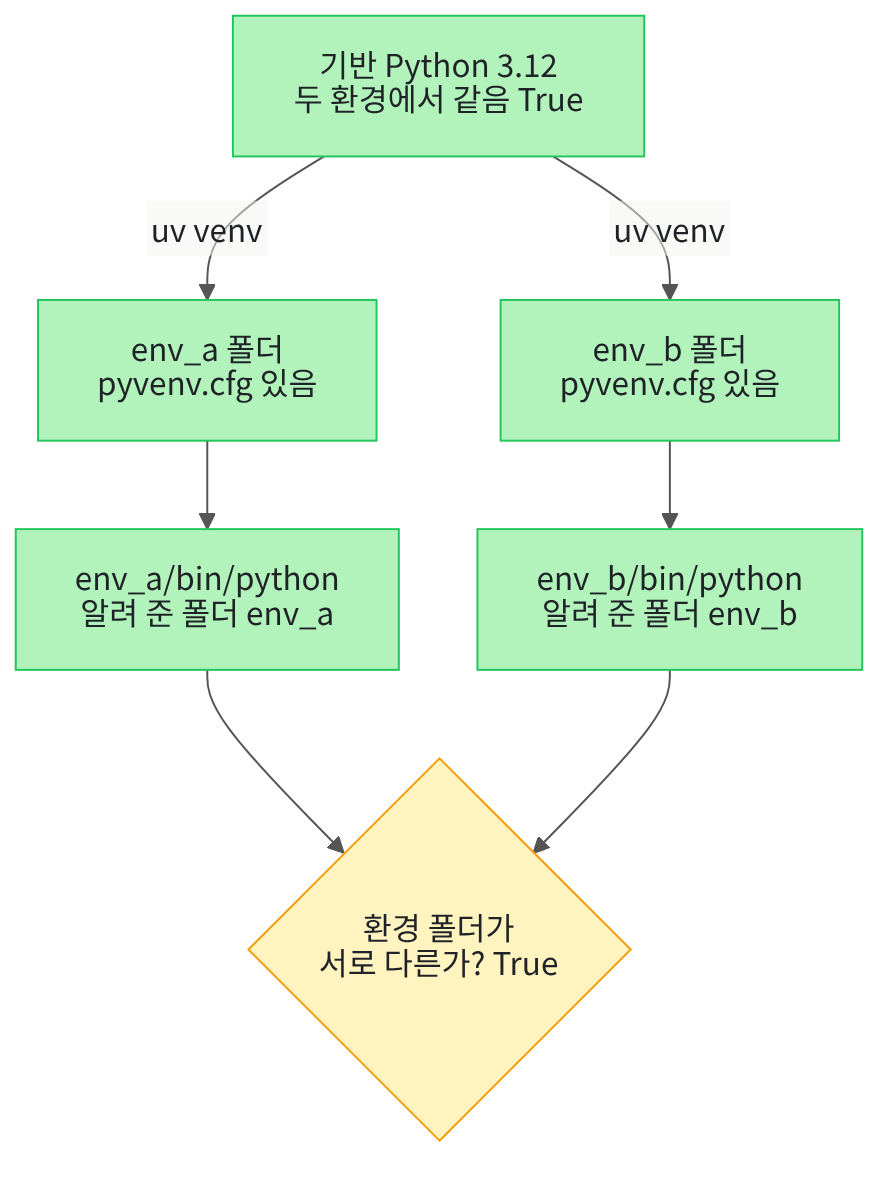

위에서 아래로 읽습니다. 초록 상자는 폴더와 실행 파일이고, 노란 마름모는 비교입니다.
같은 기반 Python에서 만든 두 환경이지만 환경 폴더는 `env_a`와 `env_b`로 따로 있습니다.

## 1. 준비

이 절도 설치할 패키지가 없습니다. 이번에도 Python에 처음부터 들어 있는 기능만 여섯 가지 불러옵니다.
코드에서 `import` 뒤에 적어 불러오는 Python 기능 묶음 한 단위를 모듈(module)이라고 합니다.
모듈 `platform`은 1절에서 버전을 확인할 때 썼습니다. 모듈 `tempfile`과 경로 기능 `Path`는 2절에서 임시 폴더를 만들 때 썼습니다.

새로 쓰는 것은 셋입니다. 모듈 `sys`는 실행 중인 Python의 정보를 알려 줍니다.
모듈 `shutil`은 명령의 위치를 찾고, 모듈 `subprocess`는 노트북 안에서 다른 프로그램을 실행합니다.

In [1]:
# 이 절에서 쓰는 Python 기본 기능을 불러옵니다
import platform
import shutil
import subprocess
import sys
import tempfile
from pathlib import Path

print("불러오기 완료")

불러오기 완료


**결과 읽기** — `불러오기 완료`가 보이면 다음 셀로 넘어갑니다.

## 2. 이 노트북의 Python 확인하기

1절에서 본 버전 확인을 다시 하고, 이번에는 가상환경 안인지도 확인합니다.
값 `sys.prefix`는 지금 쓰는 환경 폴더의 위치입니다. 값 `sys.base_prefix`는 그 환경을 만든 기반 Python의 위치입니다.
가상환경 안에서 실행하면 두 위치가 다릅니다. 기호 `!=`는 두 값이 다른지 묻고, 다르면 `True`를 만듭니다.

In [2]:
# 이 노트북을 실행하는 Python의 버전과 가상환경 여부를 확인합니다
python_version = platform.python_version()
is_python_312 = python_version.startswith("3.12")
print("Python 버전:", python_version)
print("3.12 버전인가:", is_python_312)
# 환경 폴더와 기반 Python 폴더가 다르면 가상환경 안에서 실행 중입니다
kernel_in_venv = sys.prefix != sys.base_prefix
print("가상환경 안에서 실행 중인가:", kernel_in_venv)

Python 버전: 3.12.13
3.12 버전인가: True
가상환경 안에서 실행 중인가: True


**결과 읽기** — Python 버전은 `3.12.13`이고, 3.12 버전인지와 가상환경 안인지 모두 `True`입니다.
위치 자체는 사람마다 달라서 출력하지 않았습니다.
가상환경 안인지가 `False`로 나오면 오른쪽 위 커널 선택에서 실습 폴더의 `.venv`를 다시 고릅니다.

## 3. uv 명령 찾기

노트북에서 uv 명령을 실행하려면 먼저 uv가 어디 있는지 알아야 합니다.
함수 `shutil.which()`는 이 노트북의 Python이 찾을 수 있는 명령의 위치를 글자로 반환합니다. 찾지 못하면 값이 없다는 뜻의 `None`을 반환합니다.
검사 줄 `assert`는 1절에서 배웠습니다. 명령 uv를 찾지 못하면 뒤의 셀이 실패하므로 여기서 먼저 멈춥니다.

설치 전에 열어 둔 VS Code에서는 새 터미널에서 uv가 되어도 노트북이 찾지 못할 수 있습니다. 이때는 VS Code를 다시 엽니다.
이 경우는 이번에 실행하지 않았습니다.

In [3]:
# 2절에서 설치한 uv 명령이 어디 있는지 찾습니다
uv_path = shutil.which("uv")
# 위치를 찾았으면 uv_path는 None이 아닙니다
found_uv = uv_path is not None
print("uv를 찾았는가:", found_uv)
# 찾지 못했다면 여기서 멈추고, 2절의 설치 확인 순서를 다시 봅니다
assert found_uv

uv를 찾았는가: True


**결과 읽기** — `True`입니다. 노트북에서도 uv 명령을 찾았습니다. 검사 줄에서 멈추지 않았습니다.
찾은 위치는 컴퓨터마다 달라서 출력하지 않았습니다.

## 4. 연습용 폴더와 환경 이름 정하기

2절처럼 내 문서를 건드리지 않도록 임시 폴더에서 연습합니다.
임시 폴더 `workspace` 안에 두 환경 폴더 `env_a`와 `env_b`의 경로를 정합니다.
2절에서 봤듯이 경로를 이어 붙이기만 해서는 폴더가 생기지 않습니다.

In [4]:
# 2절처럼 연습용 임시 폴더를 만들고, 두 환경 폴더의 경로를 정합니다
temporary_folder = tempfile.TemporaryDirectory()
workspace = Path(temporary_folder.name)
env_a = workspace / "env_a"
env_b = workspace / "env_b"
# 경로만 정했으므로 아직 두 폴더는 없습니다
print("env_a 폴더가 있는가:", env_a.is_dir())
print("env_b 폴더가 있는가:", env_b.is_dir())

env_a 폴더가 있는가: False
env_b 폴더가 있는가: False


**결과 읽기** — 두 줄 모두 `False`입니다. 아직 환경 폴더를 만들지 않았습니다.

## 5. 가상환경 두 개 만들기

가상환경을 만드는 명령은 `uv venv`입니다. 터미널이라면 `uv venv --python 3.12 --no-project env_a`처럼 입력합니다.
노트북에서는 명령 조각을 목록에 차례로 담아 함수 `subprocess.run()`에 넣습니다.

옵션 `--python 3.12`는 Python 버전을 정합니다. 옵션 `--no-project`는 프로젝트 설정을 읽지 않고 환경만 만들게 합니다.
옵션 `--quiet`는 진행 메시지를 줄입니다. 인자 `check=True`는 명령이 실패하면 셀 실행도 멈추게 합니다.

In [5]:
# uv venv 명령으로 env_a 폴더에 Python 3.12 가상환경을 만듭니다
# 목록의 첫 값은 실행할 프로그램이고, 나머지는 터미널에서 띄어 쓰던 명령 조각입니다
command_a = [uv_path, "venv", "--python", "3.12", "--no-project", "--quiet", env_a]
# subprocess.run()은 목록의 명령을 실행합니다. check=True이면 실패할 때 멈춥니다
subprocess.run(command_a, check=True)
# pyvenv.cfg는 가상환경을 만들 때 환경 폴더에 생기는 설정 파일입니다
config_a = env_a / "pyvenv.cfg"
print("env_a 폴더가 있는가:", env_a.is_dir())
print("pyvenv.cfg 파일이 있는가:", config_a.is_file())

env_a 폴더가 있는가: True
pyvenv.cfg 파일이 있는가: True


**결과 읽기** — 두 줄 모두 `True`입니다. 명령을 실행한 뒤 env_a 폴더와 설정 파일 pyvenv.cfg가 생겼습니다.

같은 명령에서 폴더 이름만 바꿔 env_b를 만듭니다. 실행 전에 예상합니다. 이번에도 두 줄 모두 `True`가 나올 것입니다.

In [6]:
# 같은 명령에서 폴더만 env_b로 바꿔 가상환경을 하나 더 만듭니다
command_b = [uv_path, "venv", "--python", "3.12", "--no-project", "--quiet", env_b]
subprocess.run(command_b, check=True)
config_b = env_b / "pyvenv.cfg"
print("env_b 폴더가 있는가:", env_b.is_dir())
print("pyvenv.cfg 파일이 있는가:", config_b.is_file())

env_b 폴더가 있는가: True
pyvenv.cfg 파일이 있는가: True


**결과 읽기** — 예상대로 두 줄 모두 `True`입니다. 임시 폴더 안에 환경 폴더가 두 개 생겼습니다.

## 6. 환경마다 들어 있는 Python 찾기

가상환경 폴더 안에는 그 환경에서 쓰는 Python 실행 파일이 있습니다.
위치는 운영체제마다 다릅니다. 운영체제가 macOS나 Linux이면 `bin/python`, Windows이면 `Scripts/python.exe`입니다.

값 `sys.platform`은 Windows에서 `"win32"`입니다. 여러 줄 `if/else`로 운영체제에 맞는 위치를 고릅니다.
경로는 2절의 `relative_to()`로 임시 폴더 기준만 출력합니다.

In [7]:
# 운영체제에 맞게 두 환경 안의 Python 실행 파일 위치를 정합니다
if sys.platform == "win32":
    python_a = env_a / "Scripts" / "python.exe"
    python_b = env_b / "Scripts" / "python.exe"
else:
    python_a = env_a / "bin" / "python"
    python_b = env_b / "bin" / "python"
# 임시 폴더 위치는 실행마다 달라서 임시 폴더 기준 경로만 출력합니다
print("env_a의 Python:", python_a.relative_to(workspace))
print("env_b의 Python:", python_b.relative_to(workspace))
print("env_a의 Python 파일이 있는가:", python_a.is_file())
print("env_b의 Python 파일이 있는가:", python_b.is_file())

env_a의 Python: env_a/bin/python
env_b의 Python: env_b/bin/python
env_a의 Python 파일이 있는가: True
env_b의 Python 파일이 있는가: True


**결과 읽기** — 경로는 `env_a/bin/python`과 `env_b/bin/python`이고, 두 파일 모두 `True`입니다.
교재 출력은 macOS·Linux 방식의 경로입니다. Windows에서는 실행하지 않았고, `Scripts` 폴더 경로가 나올 것으로 봅니다.

## 7. env_a의 Python에게 환경 폴더 묻기

이제 env_a의 Python을 직접 실행해 `sys.prefix`와 `sys.base_prefix`를 출력하게 합니다.
옵션 `-c`는 뒤에 적은 글자를 Python 코드로 실행합니다. 글자 안의 `\n`은 줄바꿈이므로 세 줄짜리 코드가 됩니다.

인자 `capture_output=True`는 출력을 화면 대신 실행 결과에 담습니다. 인자 `text=True`는 그 출력을 글자로 읽게 합니다.
담긴 출력은 결과의 `stdout`에 있고, 메서드 `splitlines()`가 줄마다 나눠 목록으로 만듭니다.

In [8]:
# env_a의 Python을 실행해 환경 폴더와 기반 Python 폴더를 한 줄씩 출력하게 합니다
check_code = "import sys\nprint(sys.prefix)\nprint(sys.base_prefix)"
run_a = [python_a, "-c", check_code]
result_a = subprocess.run(run_a, capture_output=True, text=True, check=True)
# 출력의 첫 줄은 환경 폴더, 둘째 줄은 기반 Python 폴더입니다
lines_a = result_a.stdout.splitlines()
prefix_a = Path(lines_a[0])
base_a = Path(lines_a[1])
a_in_venv = prefix_a != base_a
# 전체 경로는 사람마다 달라서 마지막 폴더 이름만 출력합니다
print("env_a Python이 알려 준 환경 폴더:", prefix_a.name)
print("env_a는 가상환경인가:", a_in_venv)

env_a Python이 알려 준 환경 폴더: env_a
env_a는 가상환경인가: True


**결과 읽기** — env_a의 Python이 알려 준 환경 폴더 이름은 `env_a`입니다. 가상환경인지는 `True`입니다.
노트북 커널이 아니라 env_a 안의 Python이 자기 환경 폴더를 알려 준 결과입니다.

같은 코드를 env_b의 Python에서 실행합니다. 실행 전에 예상합니다. 환경 폴더 이름은 `env_b`로 나올 것입니다.

In [9]:
# 같은 코드를 env_b의 Python에서 실행합니다
run_b = [python_b, "-c", check_code]
result_b = subprocess.run(run_b, capture_output=True, text=True, check=True)
lines_b = result_b.stdout.splitlines()
prefix_b = Path(lines_b[0])
base_b = Path(lines_b[1])
b_in_venv = prefix_b != base_b
print("env_b Python이 알려 준 환경 폴더:", prefix_b.name)
print("env_b는 가상환경인가:", b_in_venv)

env_b Python이 알려 준 환경 폴더: env_b
env_b는 가상환경인가: True


**결과 읽기** — 환경 폴더 이름은 예상대로 `env_b`이고, 가상환경인지도 `True`입니다.

## 8. 두 환경 비교하기

두 환경의 폴더와 기반 Python 폴더를 비교합니다.
실행 전에 예상합니다. 환경 폴더는 서로 다를 것입니다. 두 환경을 같은 `--python 3.12` 명령으로 만들었으므로 기반 Python 폴더는 같을 것입니다.

In [10]:
# 두 환경의 환경 폴더와 기반 Python 폴더를 각각 비교합니다
different_prefix = prefix_a != prefix_b
same_base = base_a == base_b
print("환경 폴더가 서로 다른가:", different_prefix)
print("기반 Python 폴더가 같은가:", same_base)
# 환경 폴더가 같다면 두 환경이 나뉘지 않은 것이므로 여기서 멈춥니다
assert different_prefix

환경 폴더가 서로 다른가: True
기반 Python 폴더가 같은가: True


**결과 읽기** — 두 줄 모두 `True`입니다. 기반 Python은 하나를 함께 쓰고, 환경 폴더는 따로 있습니다.
이번 실행에서 확인한 것은 폴더 위치입니다. 패키지가 따로 설치되는지는 다음 실험에서 확인합니다.

## 실험: 프로젝트 환경의 패키지를 새 환경에서 불러오기

이 노트북 커널의 환경에는 노트북 실행 도구 `ipykernel` 패키지가 설치되어 있습니다. 실습 폴더의 `pyproject.toml`에 적힌 패키지입니다.
새로 만든 env_a에는 아무 패키지도 설치하지 않았습니다.
실행 전에 예상합니다. 커널의 Python에서는 불러오기가 성공하고, env_a의 Python에서는 실패할 것입니다.

값 `sys.executable`은 지금 노트북을 실행하는 Python 실행 파일입니다. 실패해도 결과를 보려고 이번에는 `check=True`를 넣지 않습니다.
실행 결과의 `returncode`는 프로그램이 끝난 상태를 알려 주는 번호(종료 코드)입니다. 보통 0이면 성공이고, 0이 아니면 실패입니다.

In [11]:
# 같은 불러오기 코드를 커널의 Python과 env_a의 Python에서 각각 실행합니다
import_code = "import ipykernel"
kernel_command = [sys.executable, "-c", import_code]
env_a_command = [python_a, "-c", import_code]
kernel_run = subprocess.run(kernel_command, capture_output=True, text=True)
env_a_run = subprocess.run(env_a_command, capture_output=True, text=True)
# returncode는 보통 0이면 성공, 0이 아니면 실패입니다
print("커널 Python 종료 코드:", kernel_run.returncode)
print("env_a Python 종료 코드:", env_a_run.returncode)

커널 Python 종료 코드: 0
env_a Python 종료 코드: 1


**결과 읽기** — 커널 Python의 종료 코드는 `0`, env_a Python의 종료 코드는 `1`입니다. 예상대로 env_a에서만 실패했습니다.

실패한 이유는 오류 메시지에 있습니다. 오류 메시지는 실행 결과의 `stderr`에 담깁니다.
여러 줄 중 마지막 줄에 오류 이름과 내용이 나옵니다. 인덱스 `[-1]`은 목록의 마지막 값을 고릅니다.

In [12]:
# env_a에서 난 오류 메시지를 줄마다 나누고 마지막 줄을 읽습니다
error_lines = env_a_run.stderr.splitlines()
last_error = error_lines[-1]
print("env_a 오류 마지막 줄:", last_error)

env_a 오류 마지막 줄: ModuleNotFoundError: No module named 'ipykernel'


**결과 읽기** — 마지막 줄은 `ModuleNotFoundError: No module named 'ipykernel'`입니다.
패키지를 설치하면 그 안의 모듈을 불러올 수 있습니다. 새로 만든 env_a에는 `ipykernel` 패키지를 설치하지 않아 같은 이름의 모듈을 찾지 못했습니다.

## 값 바꿔 보기: 표준 라이브러리 불러오기

불러올 이름만 `ipykernel`에서 `json`으로 바꿔 env_a에서 다시 실행합니다.
모듈 `json`은 Python과 함께 오는 표준 라이브러리입니다. 따로 설치하지 않아도 들어 있습니다.
실행 전에 예상합니다. 이번에는 env_a에서도 종료 코드 0이 나올 것입니다.

In [13]:
# 불러올 이름만 표준 라이브러리 json으로 바꿔 env_a에서 다시 실행합니다
json_code = "import json"
json_command = [python_a, "-c", json_code]
json_run = subprocess.run(json_command, capture_output=True, text=True)
print("실행한 코드:", json_code)
print("env_a Python 종료 코드:", json_run.returncode)

실행한 코드: import json
env_a Python 종료 코드: 0


**결과 읽기** — 종료 코드는 `0`입니다. 아무 패키지도 설치하지 않은 env_a에서도 `import json`은 성공했습니다.
표준 라이브러리는 기반 Python에 들어 있습니다. 따로 설치하는 패키지만 환경마다 나뉩니다.

## 9. 임시 폴더 정리하기

연습이 끝났으므로 2절처럼 `cleanup()`으로 임시 폴더를 지웁니다. 안에 만든 두 가상환경도 함께 지워집니다.
실습 폴더의 `.venv`는 이 임시 폴더 밖에 있으므로 지워지지 않습니다.

In [14]:
# 연습용 임시 폴더와 그 안의 두 가상환경을 함께 지웁니다
temporary_folder.cleanup()
print("임시 폴더가 남아 있는가:", workspace.is_dir())

임시 폴더가 남아 있는가: False


**결과 읽기** — `False`입니다. 임시 폴더와 env_a, env_b가 지워졌습니다.

## 정리

- 가상환경 안에서 실행한 Python은 자기 환경 폴더(`sys.prefix`)를 알려 줍니다. 두 환경은 서로 다른 폴더를 알려 줬습니다.
- 두 환경은 같은 기반 Python을 함께 썼습니다. 표준 라이브러리 `json`은 새 환경에서도 불러왔습니다.
- 커널 환경에 설치된 `ipykernel`은 env_a에서 불러오지 못했습니다. 패키지는 설치한 환경에서만 쓸 수 있습니다.

패키지의 서로 다른 버전을 두 환경에 설치하는 실험은 이번에 실행하지 않았습니다.
다음 절에서는 이 실습 폴더의 환경으로 첫 스크립트 `hello.py`를 실행합니다.